# TS_3. Stationarity and correlation analysis

In [1]:
import warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from statsmodels.tsa.stattools import adfuller, kpss, ccf
from statsmodels.tsa.arima_process import ArmaProcess
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from arch.unitroot import PhillipsPerron, DFGLS
from pmdarima.arima import ndiffs, nsdiffs
warnings.filterwarnings("ignore")

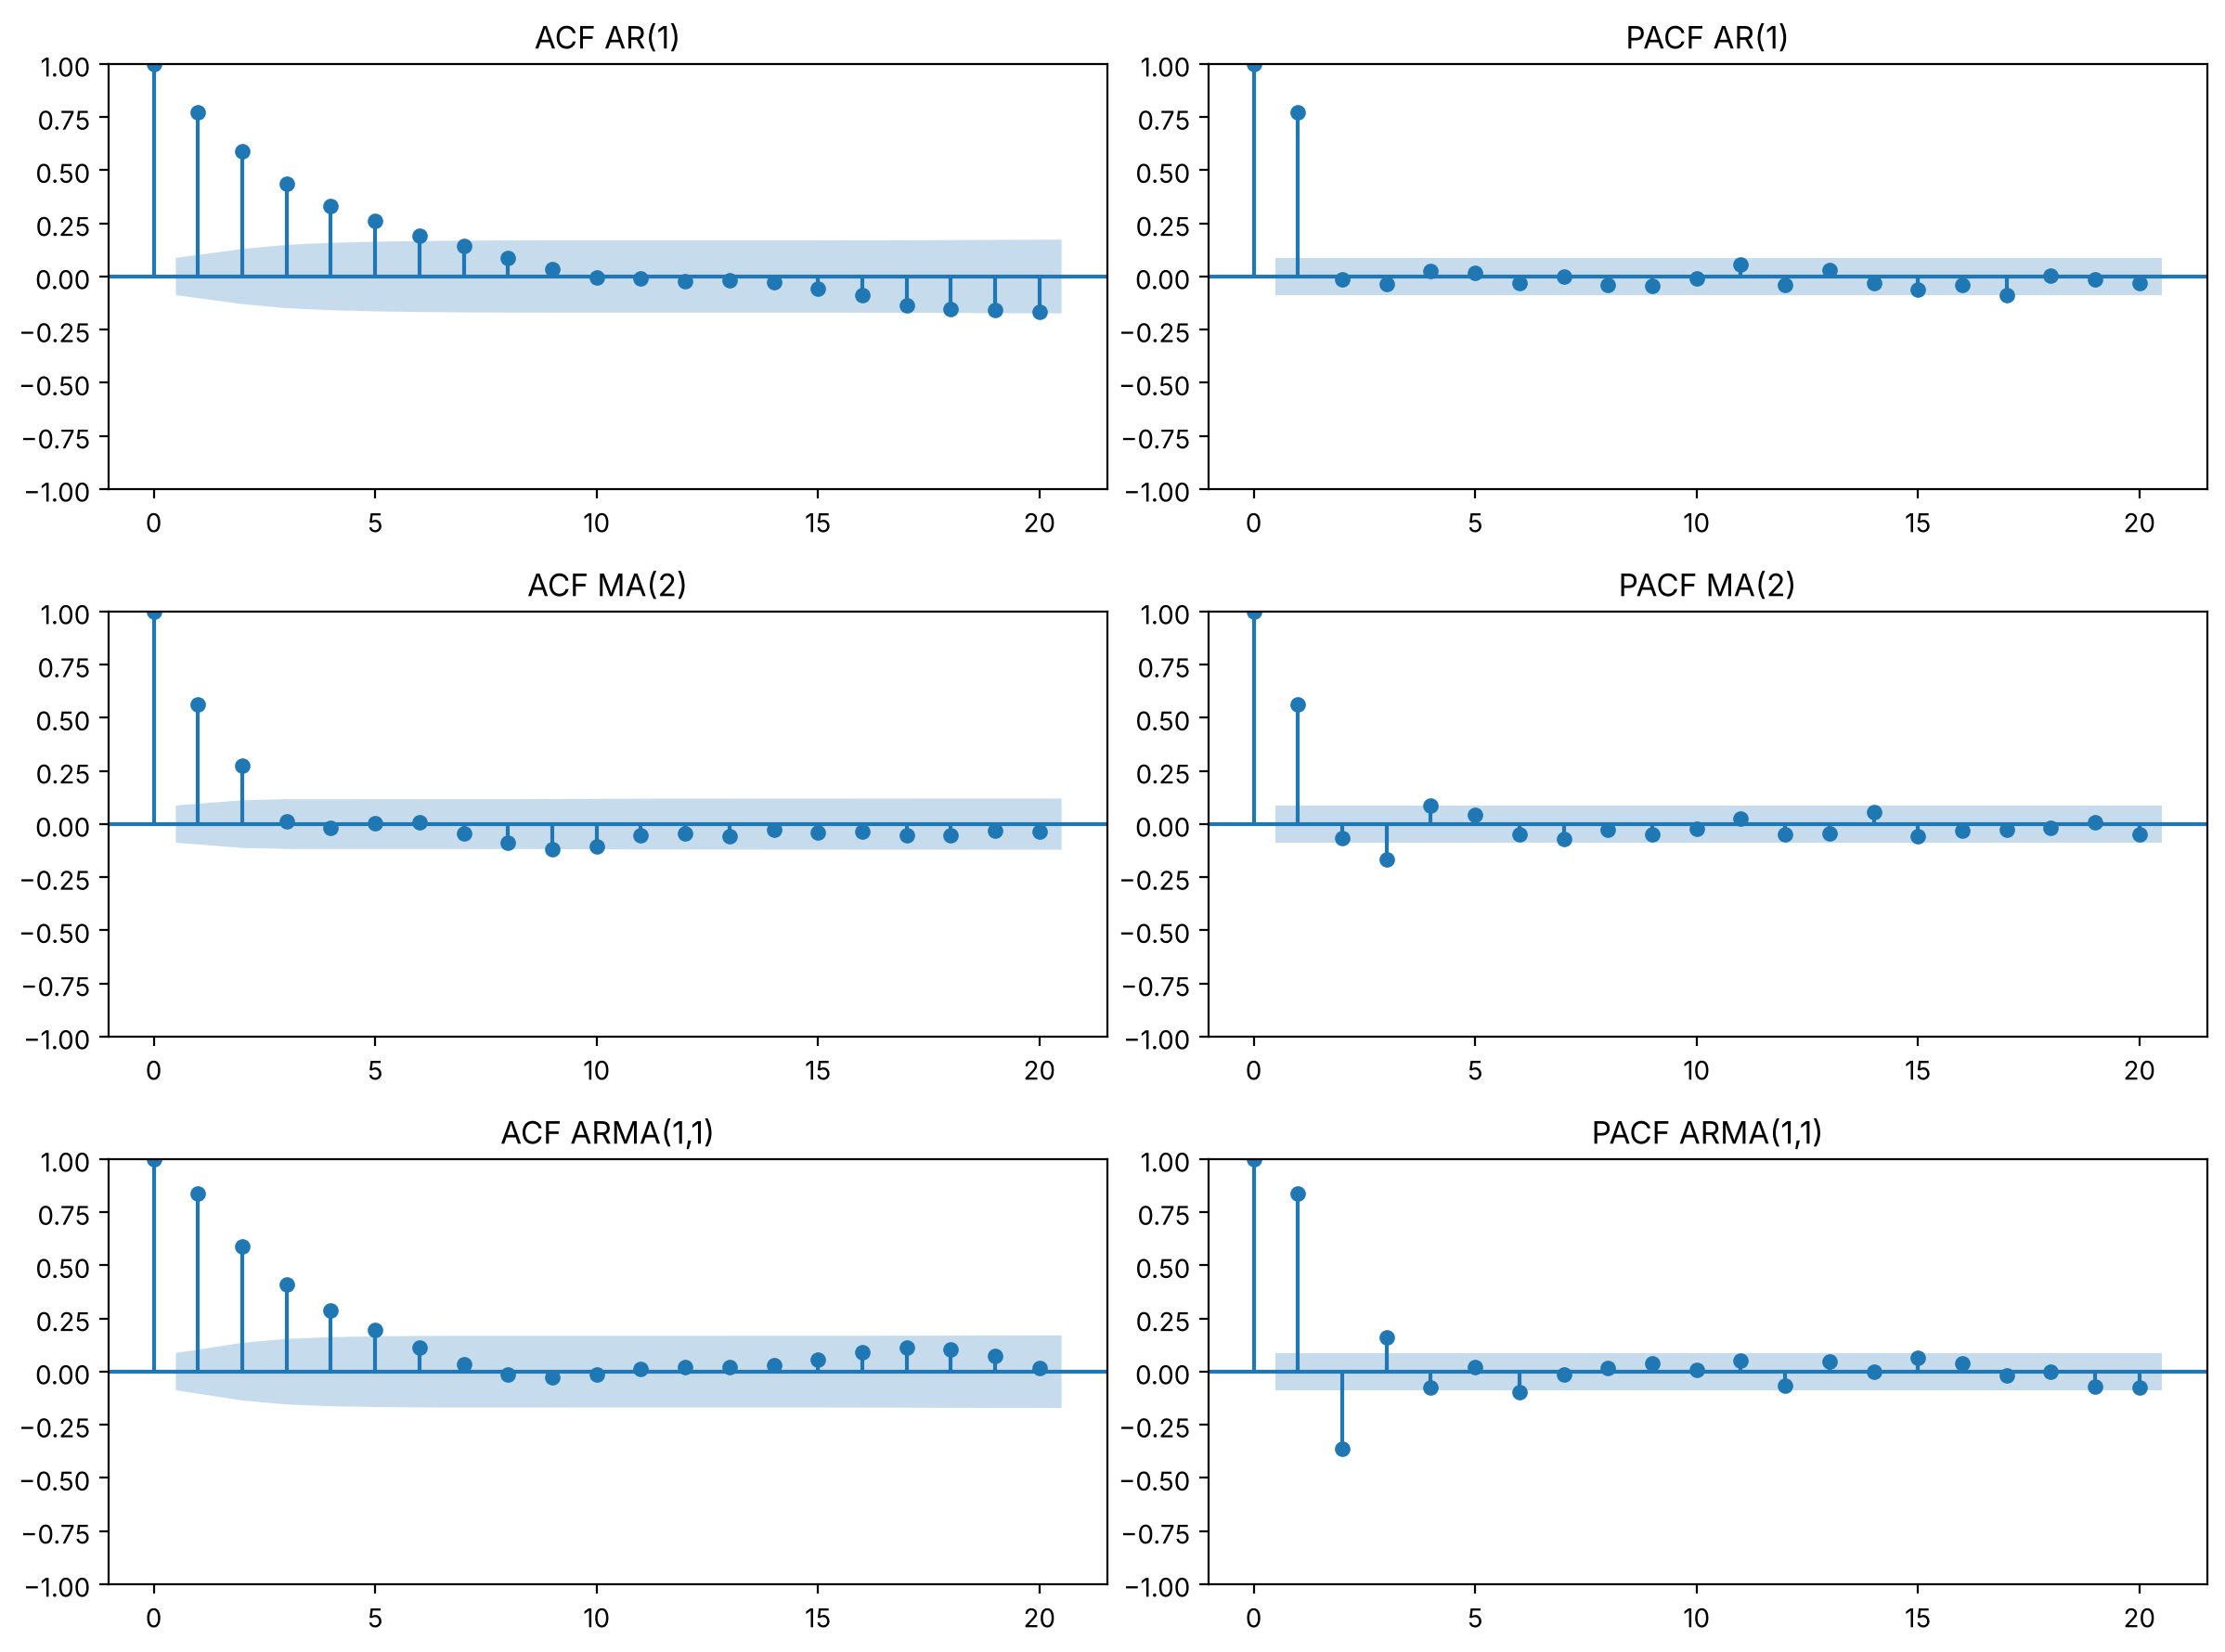

In [2]:
# ACF / PACF for AR, MA, ARMA
rng = np.random.default_rng(0)
procs = {"AR(1)": ([1, -0.8], [1]), "MA(2)": ([1], [1, 0.6, 0.4]), "ARMA(1,1)": ([1, -0.7], [1, 0.5])}
fig, ax = plt.subplots(3, 2, figsize=(12, 9))
for i, (name, (ar, ma)) in enumerate(procs.items()):
    x = ArmaProcess(ar, ma).generate_sample(500)
    plot_acf(x, lags=20, ax=ax[i, 0], title=f"ACF {name}")
    plot_pacf(x, lags=20, ax=ax[i, 1], title=f"PACF {name}")
plt.tight_layout(); plt.show()

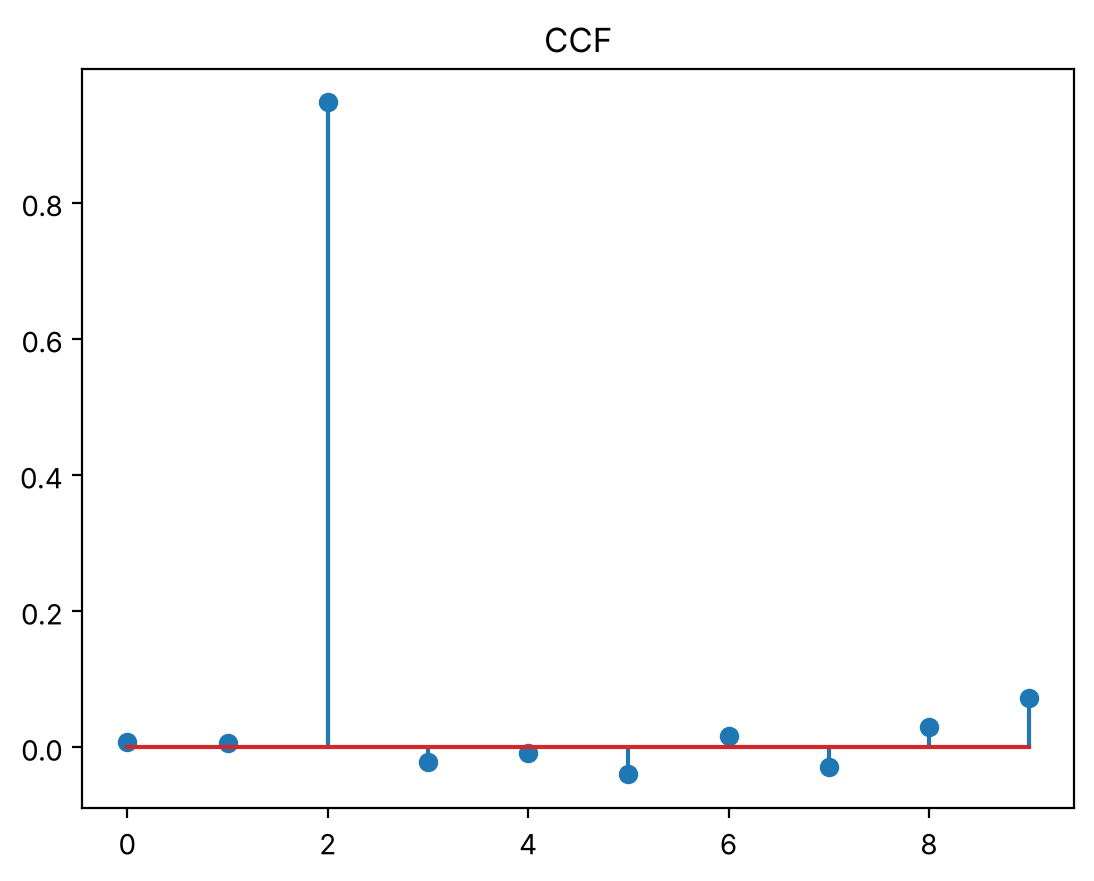

In [3]:
# CCF: x leads y by 2
x = rng.normal(size=500)
yy = 0.8 * np.roll(x, 2) + 0.3 * rng.normal(size=500)
plt.stem(ccf(yy, x)[:10]); plt.title("CCF"); plt.show()

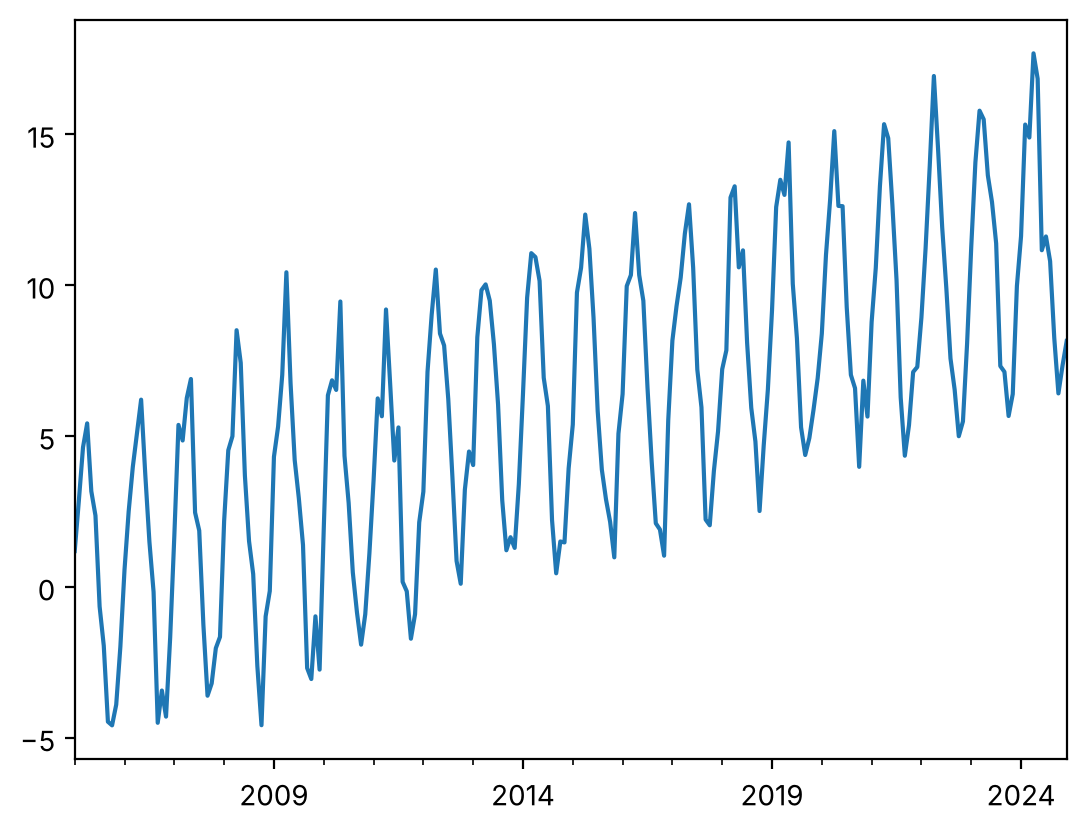

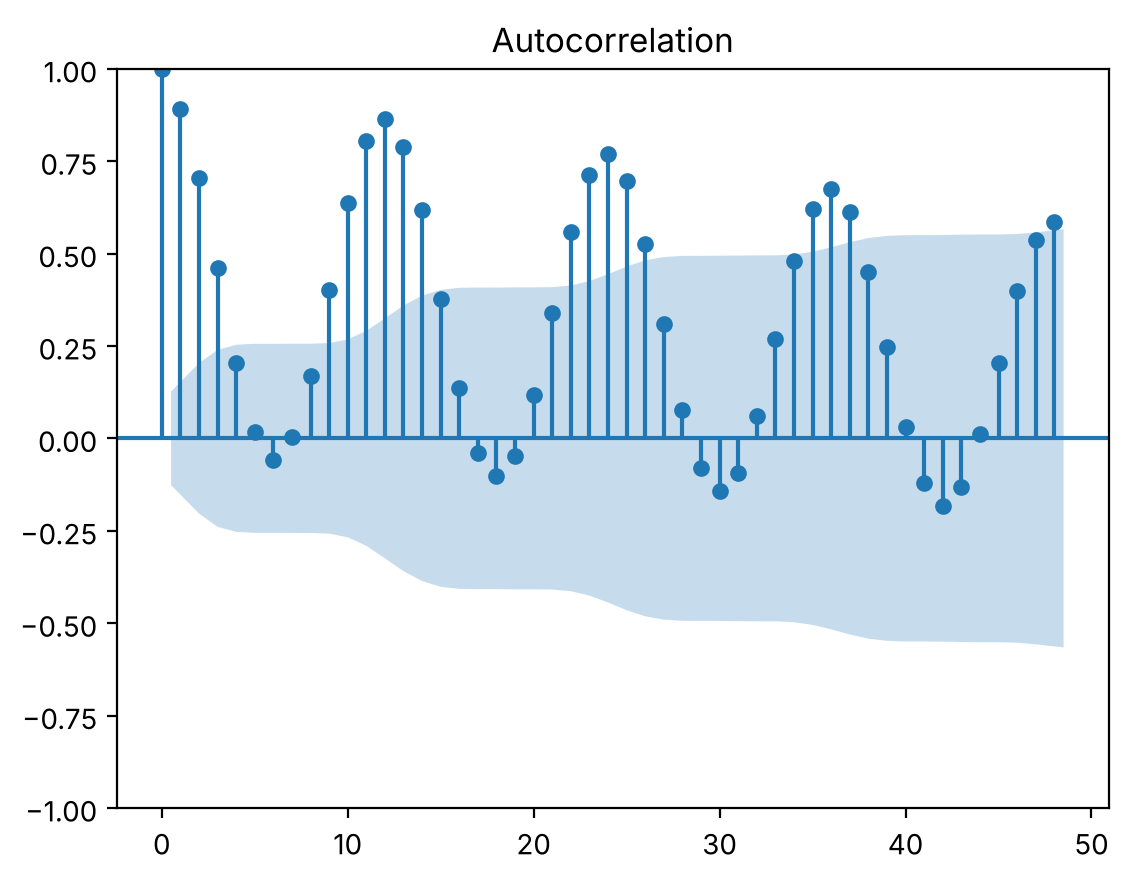

In [4]:
t = np.arange(240)
y = pd.Series(0.05 * t + 5 * np.sin(2 * np.pi * t / 12) + rng.normal(size=240),
              index=pd.date_range("2005-01", periods=240, freq="MS"))
y.plot(); plt.show()
plot_acf(y, lags=48); plt.show()

In [5]:
def report_tests(x, name):
    x = x.dropna()
    print(f"{name}: ADF p={adfuller(x)[1]:.4f}, PP p={PhillipsPerron(x).pvalue:.4f}, "
          f"DF-GLS p={DFGLS(x).pvalue:.4f}, KPSS p={kpss(x, nlags='auto')[1]:.4f}")

report_tests(y, "level")
report_tests(y.diff(), "diff1")
report_tests(y.diff(12), "sdiff12")
report_tests(y.diff().diff(12), "diff1+sdiff12")

level: ADF p=0.8694, PP p=0.0090, DF-GLS p=0.9999, KPSS p=0.0100
diff1: ADF p=0.0000, PP p=0.0000, DF-GLS p=0.6651, KPSS p=0.1000
sdiff12: ADF p=0.0001, PP p=0.0000, DF-GLS p=0.0899, KPSS p=0.1000
diff1+sdiff12: ADF p=0.0000, PP p=0.0000, DF-GLS p=0.0005, KPSS p=0.1000


In [6]:
print("d =", ndiffs(y, test="kpss"), "D =", nsdiffs(y, m=12, test="ocsb"))

d = 1 D = 0


lambda = 0.0


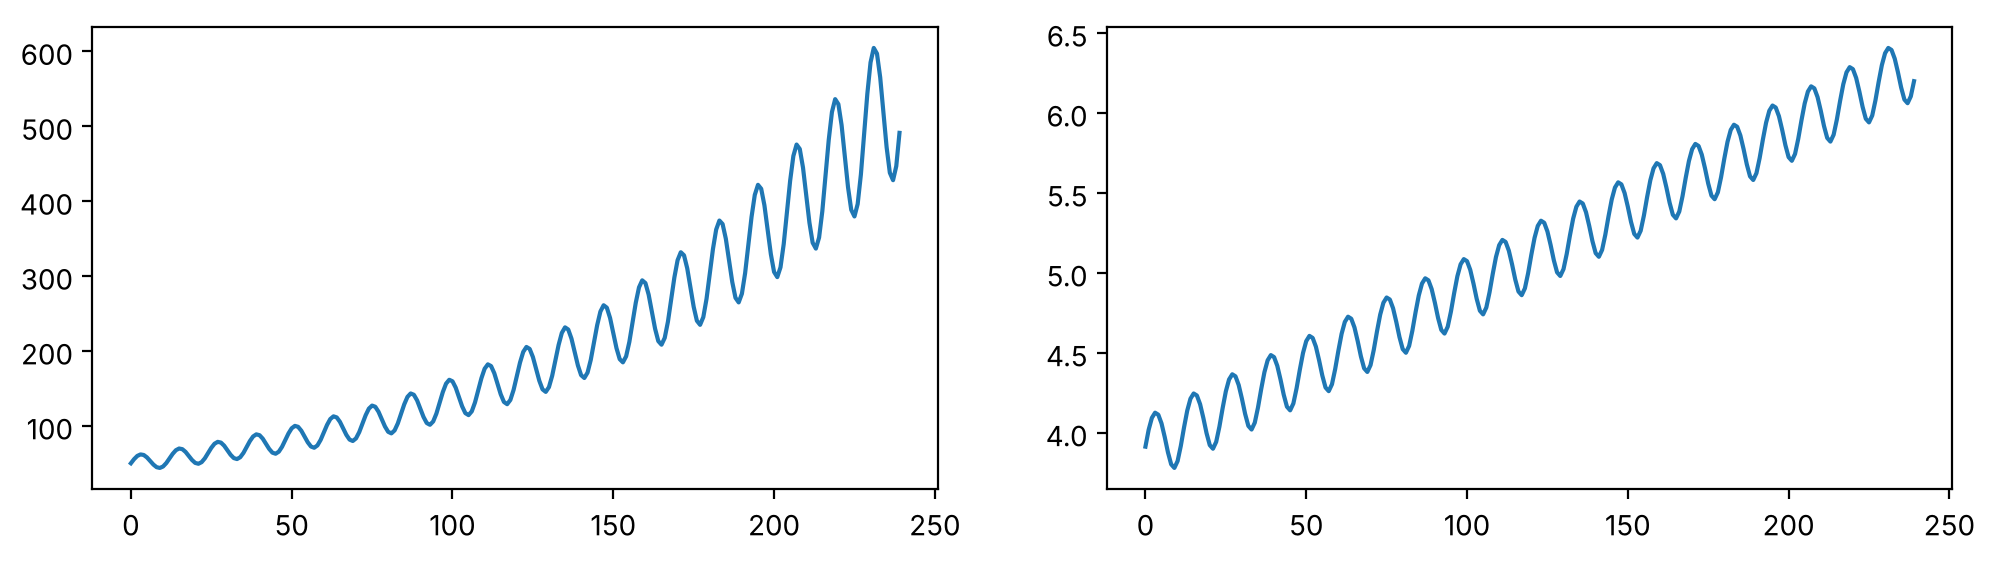

In [7]:
# Box-Cox for growing variance
ym = pd.Series(50 * np.exp(0.01 * t) * (1 + 0.2 * np.sin(2 * np.pi * t / 12)))
yb, lam = stats.boxcox(ym)
print("lambda =", round(lam, 3))
fig, ax = plt.subplots(1, 2, figsize=(12, 3))
ax[0].plot(ym); ax[1].plot(yb); plt.show()

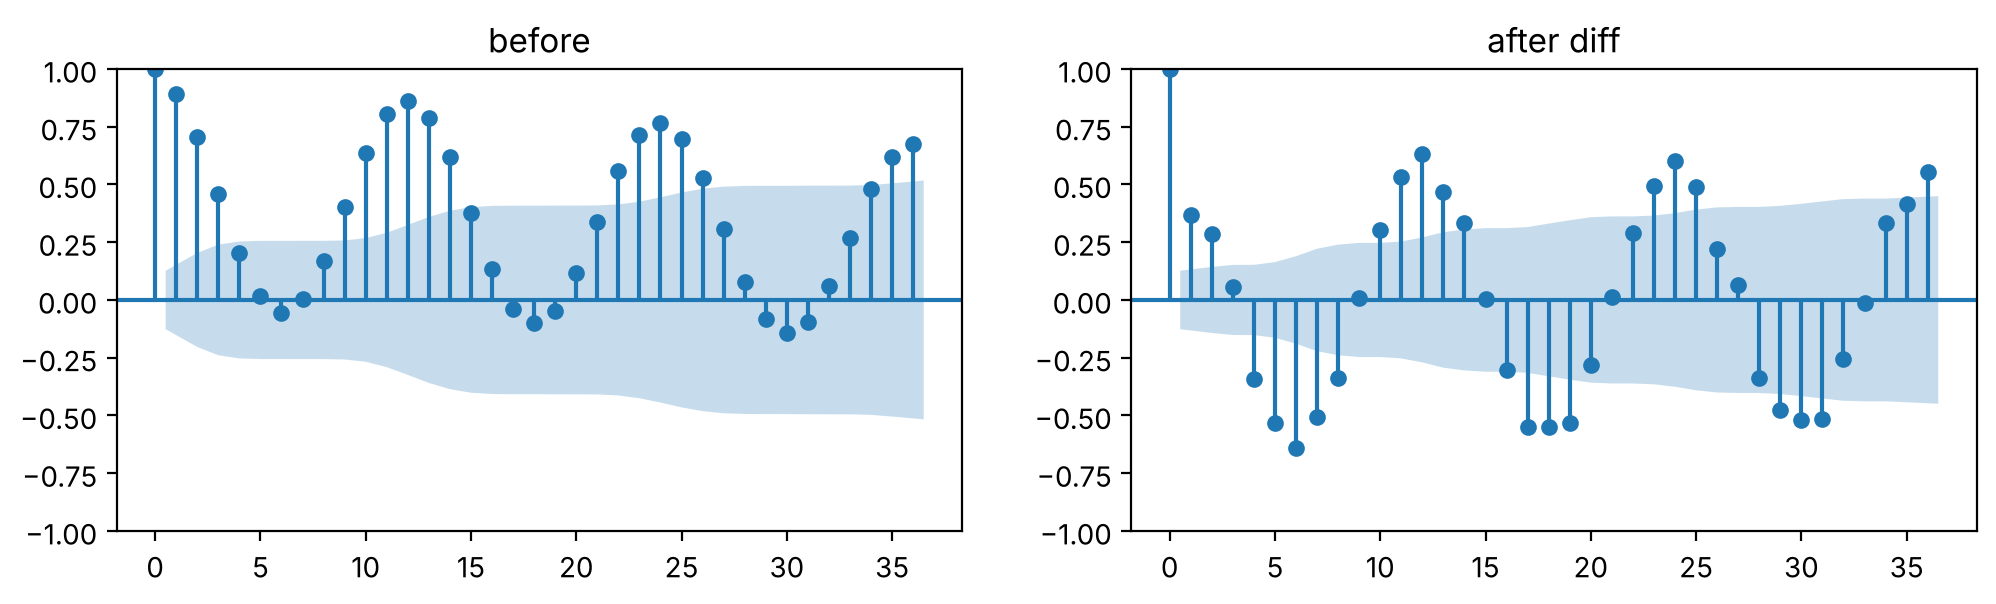

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3))
plot_acf(y, lags=36, ax=ax[0], title="before")
plot_acf(y.diff().dropna(), lags=36, ax=ax[1], title="after diff"); plt.show()